IQR, Z-SCORE

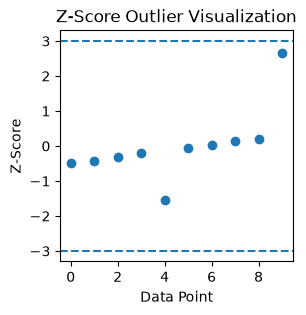

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, -20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

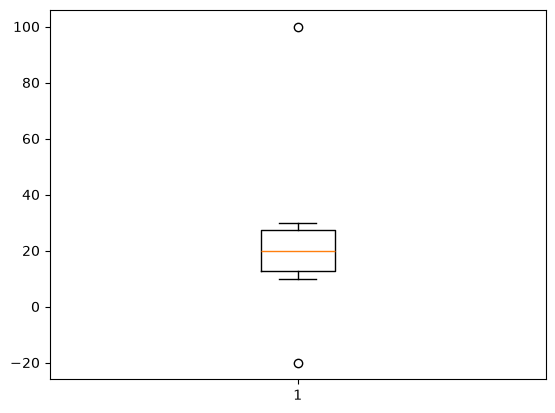

In [6]:
plt.boxplot(data)
plt.show()

REMOVAL    #removal of outliers

In [8]:
import seaborn as sns
import pandas as pd

df=sns.load_dataset('tips')

In [22]:
df.shape

(244, 7)

In [9]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


{'whiskers': [<matplotlib.lines.Line2D at 0x21d442f5e50>,
 'caps': [<matplotlib.lines.Line2D at 0x21d442f60d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x21d442f5d10>],
 'medians': [<matplotlib.lines.Line2D at 0x21d442f6350>],
 'fliers': [<matplotlib.lines.Line2D at 0x21d442f6490>],
 'means': []}

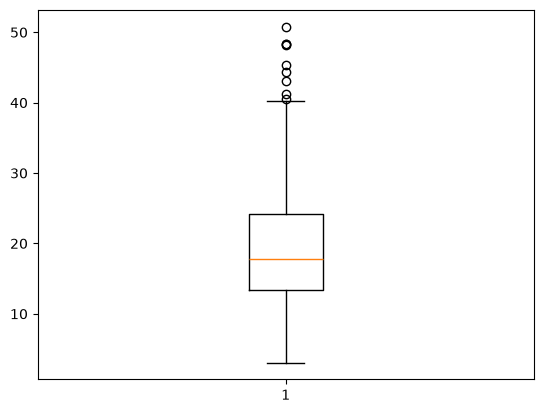

In [21]:
plt.boxplot(df['total_bill'])

In [19]:
q1= df['total_bill'].quantile(0.25)
q3= df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower= q1-1.5*iqr
upper= q3+1.5*iqr
print(lower,upper)

(df['total_bill']<upper) &  (df['total_bill']>lower)

df[(df['total_bill']<upper) &  (df['total_bill']>lower)]


iqr----- 10.779999999999998
-2.8224999999999945 40.29749999999999


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


CAPPING       #replacing of outliers, using clip function

In [34]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


{'whiskers': [<matplotlib.lines.Line2D at 0x21d4421a210>,
 'caps': [<matplotlib.lines.Line2D at 0x21d44219810>,
 'boxes': [<matplotlib.lines.Line2D at 0x21d443e9a90>],
 'medians': [<matplotlib.lines.Line2D at 0x21d442196d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x21d44219950>],
 'means': []}

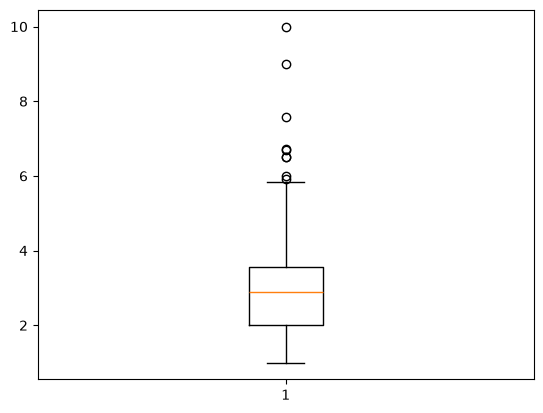

In [27]:
plt.boxplot(df['tip'])

In [28]:
q1= df['tip'].quantile(0.25)
q3= df['tip'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower= q1-1.5*iqr
print('lower------',lower)
upper= q3+1.5*iqr
print('upper-------',upper)

iqr----- 1.5625
lower------ -0.34375
upper------- 5.90625


{'whiskers': [<matplotlib.lines.Line2D at 0x21d4449d310>,
 'caps': [<matplotlib.lines.Line2D at 0x21d4449d590>,
 'boxes': [<matplotlib.lines.Line2D at 0x21d4449d1d0>],
 'medians': [<matplotlib.lines.Line2D at 0x21d4449d810>],
 'fliers': [<matplotlib.lines.Line2D at 0x21d4449d950>],
 'means': []}

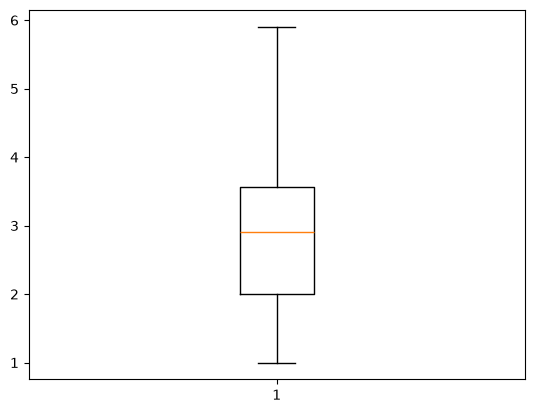

In [33]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

COLUMN TRANSFORMER

In [36]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


In [42]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder,LabelEncoder,MinMaxScaler
from sklearn.compose import ColumnTransformer

In [39]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [52]:
num_fea=['total_bill']
ohe_fea=['sex', 'smoker']
min_max=['tip']

In [61]:
transformer=ColumnTransformer(
transformers=[('num',StandardScaler(),num_fea),
('cat',OneHotEncoder(drop='first'),ohe_fea),
('min_max',MinMaxScaler(),min_max)
],remainder='passthrough'
)

In [62]:
transformer.fit_transform(df)

array([[-0.3147113050904943, 0.0, 0.0, ..., 'Sun', 'Dinner', 2],
       [-1.0632353132988692, 1.0, 0.0, ..., 'Sun', 'Dinner', 3],
       [0.13777989987156145, 1.0, 0.0, ..., 'Sun', 'Dinner', 3],
       ...,
       [0.3246295019205694, 1.0, 1.0, ..., 'Sat', 'Dinner', 2],
       [-0.2212865040659901, 1.0, 0.0, ..., 'Sat', 'Dinner', 2],
       [-0.11322890288102155, 0.0, 0.0, ..., 'Thur', 'Dinner', 2]],
      shape=(244, 7), dtype=object)

In [66]:
pd.DataFrame(transformer.fit_transform(df), columns=transformer.get_feature_names_out())

,num__total_bill,cat__sex_Male,cat__smoker_Yes,min_max__tip,remainder__day,remainder__time,remainder__size
0,-0.314711,0.0,0.0,0.002038,Sun,Dinner,2
1,-1.063235,1.0,0.0,0.134522,Sun,Dinner,3
2,0.13778,1.0,0.0,0.509554,Sun,Dinner,3
3,0.438315,1.0,0.0,0.470828,Sun,Dinner,2
4,0.540745,0.0,0.0,0.531975,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,1.0,0.0,1.0,Sat,Dinner,3
240,0.832275,0.0,1.0,0.203822,Sat,Dinner,2
241,0.32463,1.0,1.0,0.203822,Sat,Dinner,2
242,-0.221287,1.0,0.0,0.152866,Sat,Dinner,2
